# Diffusion Models

This notebook has a minimal smoke test for loading the main diffusion backbones and generating a few example images with standard sampling.

For details about the model configurations and sampling pipeline, see the `src/model_utils.py` file.

In [1]:
from pathlib import Path

from IPython.display import display
from PIL import Image

from zigzag_project.model_utils import (
    DREAM_SHARPER,
    SDXL,
    free_pipeline,
    generate_images_standard,
    list_model_configs,
    load_pipeline_standard,
)

OUTPUT_DIR = Path.cwd().parent / "outputs" / "smoke_test_examples"
SEED = 42


# Model Configurations

In [2]:
list_model_configs()

{'sdxl': {'model_id': 'stabilityai/stable-diffusion-xl-base-1.0',
  'num_inference_steps': 50,
  'guidance_scale': 5.5,
  'height': 1024,
  'width': 1024},
 'dreamshaper-xl-v2-turbo': {'model_id': 'Lykon/dreamshaper-xl-v2-turbo',
  'num_inference_steps': 4,
  'guidance_scale': 3.5,
  'height': 1024,
  'width': 1024}}

# Example Prompts

In [3]:
example_prompts = [
    "An elephant in a room full of glassware.",
    # "A dog buying groceries.",
    # "A heart-shaped light blue bomb that explodes inside a pancake."
]

# SDXL Example

### Load the Model

In [4]:
pipeline_sdxl = load_pipeline_standard(SDXL)

/Users/dicisnerosacev/Documents/university/generative-modelling/.venv/lib/python3.10/site-packages/huggingface_hub/file_download.py:1150: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

### Generate Images

In [5]:
result_sdxl = generate_images_standard(
    pipeline_sdxl,
    example_prompts,
    SDXL,
    seed=SEED,
    output_dir=OUTPUT_DIR,
)

result_sdxl


  0%|          | 0/50 [00:00<?, ?it/s]

[PosixPath('/Users/dicisnerosacev/Documents/university/generative-modelling/outputs/smoke_test_examples/sdxl_000_20260517_133233.png')]

### Display One Example

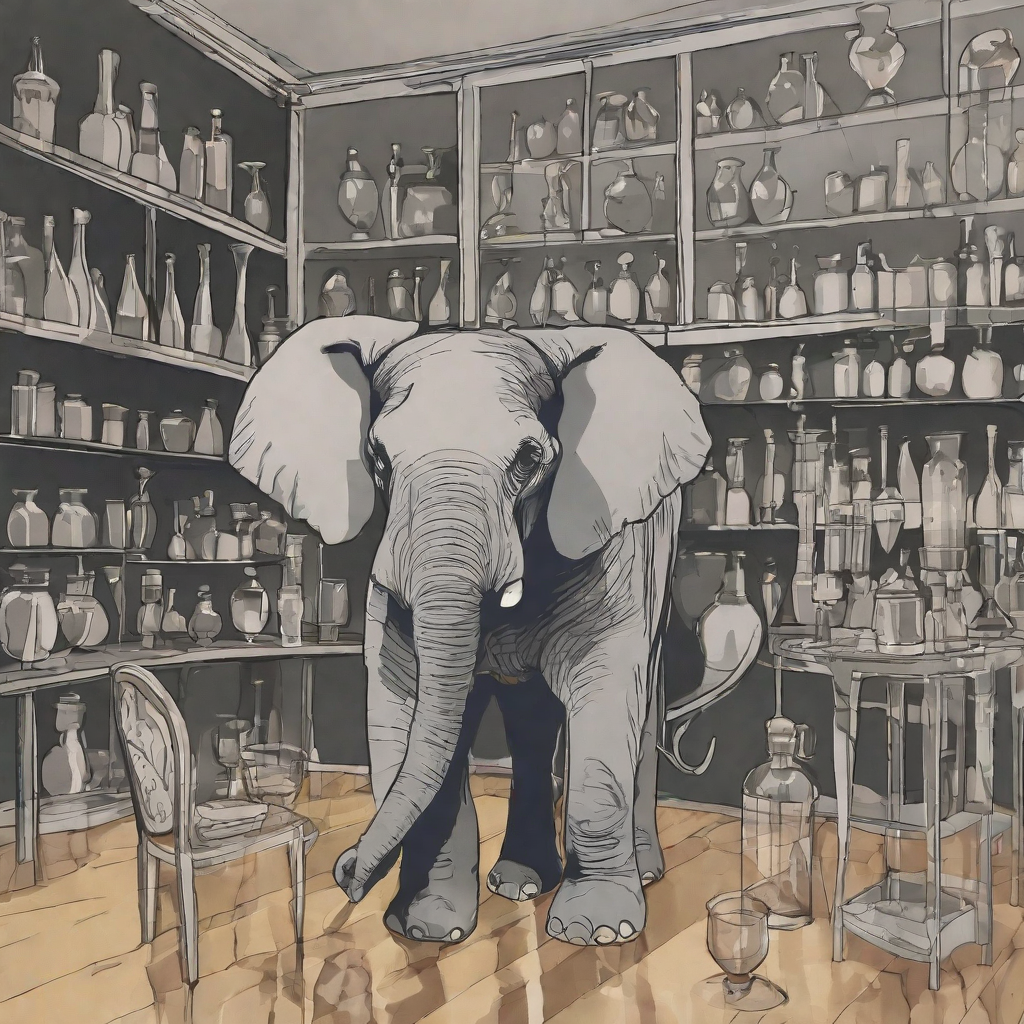

In [6]:
display(Image.open(result_sdxl[0]))

### Free Memory Before Loading Another Model

In [7]:
free_pipeline(pipeline_sdxl)
pipeline_sdxl = None

# DreamSharper XL Turbo Example

### Load the Model

In [ ]:
pipeline_dream_sharper = load_pipeline_standard(DREAM_SHARPER)

/Users/dicisnerosacev/Documents/university/generative-modelling/.venv/lib/python3.10/site-packages/huggingface_hub/file_download.py:1150: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


model_index.json:   0%|          | 0.00/671 [00:00<?, ?B/s]

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/558 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/560 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/856 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/602 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/10.3G [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

### Generate Images

In [9]:
result_dream_sharper = generate_images_standard(
    pipeline_dream_sharper,
    example_prompts,
    DREAM_SHARPER,
    seed=SEED,
    output_dir=OUTPUT_DIR,
)

result_dream_sharper


  0%|          | 0/4 [00:00<?, ?it/s]

[PosixPath('/home/lenka-hake/Documents/GM/generative-modelling/outputs/smoke_test_examples/dreamshaper-xl-v2-turbo_000_20260516_231309.png')]

### Display One Example

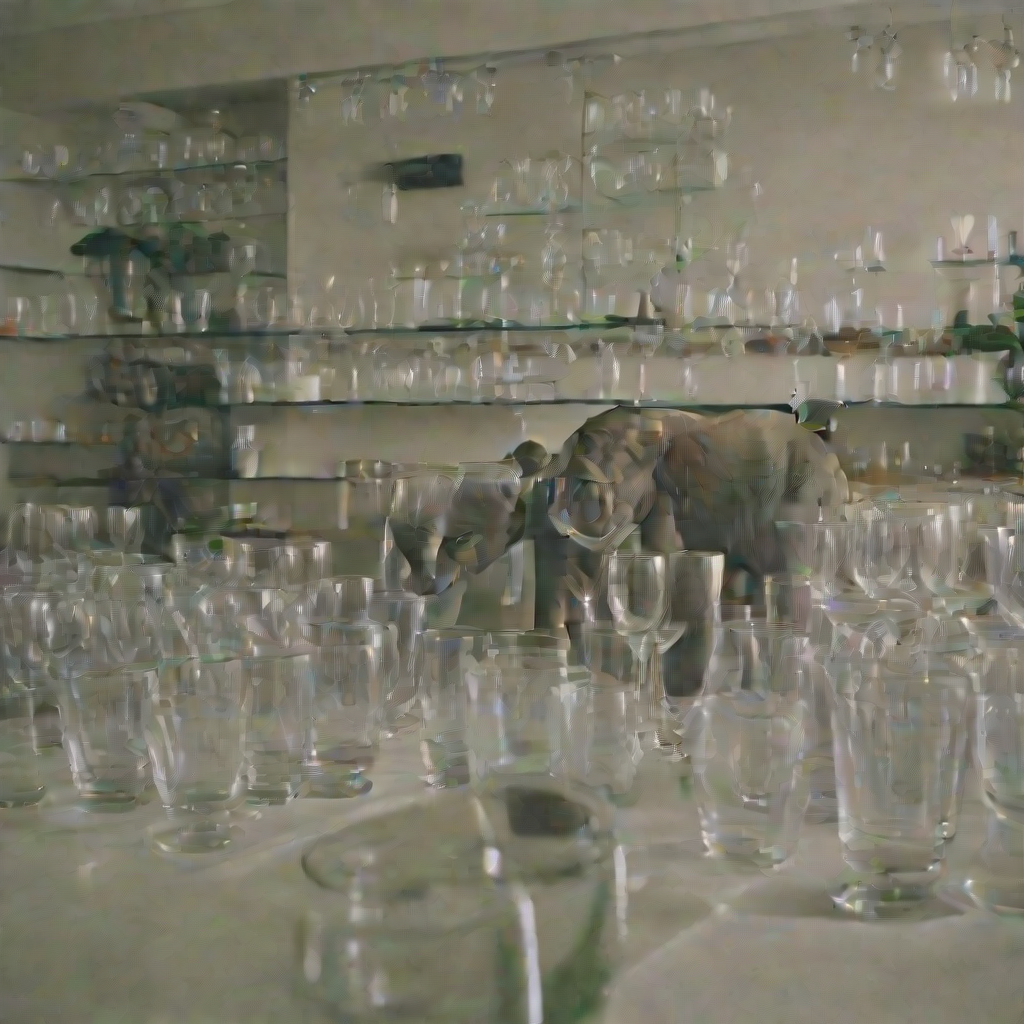

In [10]:
display(Image.open(result_dream_sharper[0]))

### Free Memory Before Loading Another Model

In [11]:
free_pipeline(pipeline_dream_sharper)
pipeline_dream_sharper = None